自定义函数 kMeans 聚类结果的兰德指数:0.7302
cluster 的 KMeans 聚类结果的兰德指数:0.7302

轮廓系数峰值=0.6810,此时簇数目 k=2。


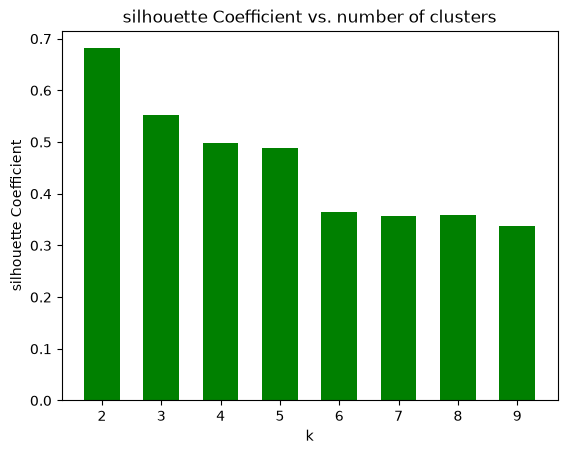

In [14]:
# -*- coding: utf-8 -*-
"""
《数据科学基础》第六章 —— K 均值聚类（K-Means）算法
来源：PDF 第 303~307 页（印刷页码约 295~299 页）

代码已根据 PDF 原始扫描画面逐行核对，修正了 OCR 自动识别稿中的
引号、括号、下标、运算符（— 还原为 -，minlndex 还原为 minIndex 等）错误。

运行依赖：
    numpy、scikit-learn、matplotlib
    （sklearn 新版中 KMeans 需显式指定 n_clusters，第 307 页的 KMeans(k)
      为旧版写法，已兼容修正为 KMeans(n_clusters=k)）
"""

import numpy as np

# ----------------------------------------------------------------------
# 1. 计算两向量的欧氏距离
# ----------------------------------------------------------------------
def distEclud(vecA, vecB):
    return np.sqrt(np.sum(np.power(vecA - vecB, 2)))


# ----------------------------------------------------------------------
# 2. 随机初始化 k 个簇中心
# ----------------------------------------------------------------------
def randCent(dataSet, k):
    # 全部改用 np.array（原书用 np.mat 的 matrix 类型，在 NumPy 2.0 下会报错）
    dataSet = np.array(dataSet)
    m = dataSet.shape[1]                     # 获取特征数目 m
    centroids = np.zeros((k, m))             # 创建 k 行 m 列的全 0 矩阵
    for j in range(m):
        minJ = dataSet[:, j].min()           # 第 j 列的最小值
        maxJ = dataSet[:, j].max()           # 第 j 列的最大值
        rangeJ = float(maxJ - minJ)
        centroids[:, j] = minJ + rangeJ * np.random.rand(k)   # 随机初始化簇中心的第 j 特征列
    return centroids


# ----------------------------------------------------------------------
# 3. k 均值算法主体
# ----------------------------------------------------------------------
def kMeans(dataSet, k, distMeas=distEclud, createCent=randCent):
    dataSet = np.array(dataSet)              # 统一转为 ndarray，避免 matrix 类型
    n = dataSet.shape[0]                     # 样本数 n
    clusterAssment = np.zeros((n, 2))        # 保存簇划分结果（第 1 列为簇号，第 2 列为到簇中心距离的平方）
    centroids = createCent(dataSet, k)       # 簇中心矩阵
    clusterChanged = True
    while clusterChanged:
        clusterChanged = False
        # 遍历每个样本 i
        for i in range(n):
            minDist = np.inf
            minIndex = -1
            # 寻找最近的簇中心 j
            for j in range(k):
                distJI = distMeas(centroids[j, :], dataSet[i, :])
                if distJI < minDist:
                    minDist = distJI
                    minIndex = j
            if clusterAssment[i, 0] != minIndex:
                clusterChanged = True
            clusterAssment[i, :] = minIndex, minDist ** 2    # 将每个点分配到最近的簇
        # 更新簇中心的位置
        for cent in range(k):
            ptsInClust = dataSet[np.nonzero(clusterAssment[:, 0] == cent)[0]]
            if len(ptsInClust) > 0:
                centroids[cent, :] = np.mean(ptsInClust, axis=0)
    return centroids, clusterAssment


# ----------------------------------------------------------------------
# 4. 在 iris 数据集上使用自定义 kMeans 与 sklearn 的 KMeans 做对照
# ----------------------------------------------------------------------
def demo():
    from sklearn.datasets import load_iris
    from sklearn import metrics

    # (1) 加载数据
    iris = load_iris()
    X = iris.data
    y = iris.target

    # (2) 调用自定义的 kMeans() 构建 k=3 的 K 均值聚类模型
    mycent, clustAssment = kMeans(X, 3)

    # (3) 用 sklearn 的 KMeans 新建一个 k=3 的 K 均值聚类模型
    from sklearn.cluster import KMeans
    km = KMeans(n_clusters=3, n_init=10, random_state=0)
    km.fit(X)

    # (4) 用兰德指数（调整兰德系数）评估两个模型的聚类结果
    s_num = len(clustAssment)                                  # 样本个数
    y_ = np.array(clustAssment[:, 0]).reshape(s_num)           # 模型返回的样本标签

    # 用兰德指数评估自定义函数聚类结果
    ri1 = metrics.adjusted_rand_score(y, y_)
    print("自定义函数 kMeans 聚类结果的兰德指数:{:.4f}".format(ri1))

    # 用兰德指数评估 scikit-learn 的 KMeans 模型聚类结果
    ri2 = metrics.adjusted_rand_score(y, km.labels_)
    print("cluster 的 KMeans 聚类结果的兰德指数:{:.4f}".format(ri2))


# ----------------------------------------------------------------------
# 5. 肘部法则 / 轮廓系数：寻找最佳 k 值并画图
# ----------------------------------------------------------------------
def best_k():
    from sklearn.datasets import load_iris
    from sklearn.cluster import KMeans
    from sklearn import metrics

    iris = load_iris()
    X = iris.data

    scores = []
    ks = np.arange(2, 10)               # [2, 9]

    max_index = -1
    max_score = -1
    for k in ks:
        # 训练模型
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=0)   # 书中旧版写法为 KMeans(k)
        kmeans.fit(X)
        score = metrics.silhouette_score(X, kmeans.labels_,
                                         metric='euclidean',
                                         sample_size=len(X))
        scores.append(score)
        if score > max_score:
            max_score = score
            max_index = k
    print("\n轮廓系数峰值={:.4f},此时簇数目 k={}。".format(max_score, max_index))

    # 画出得分条形图
    import matplotlib.pyplot as plt
    plt.figure()
    plt.bar(ks, scores, width=0.6, color='g', align='center')
    plt.title('silhouette Coefficient vs. number of clusters')
    plt.xlabel('k')
    plt.ylabel('silhouette Coefficient')
    plt.show()


if __name__ == '__main__':
    demo()
    best_k()


<Axes: xlabel='sepal_length', ylabel='sepal_width'>

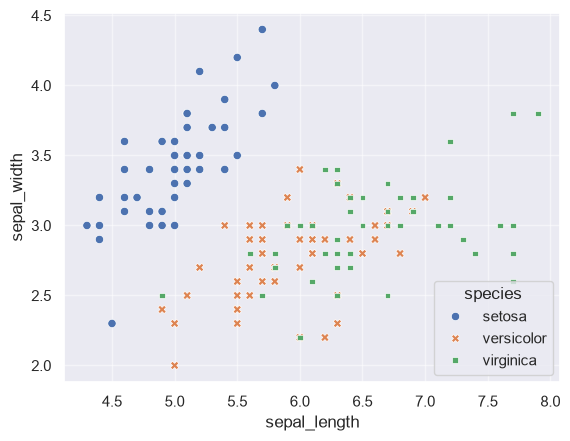

In [17]:
#画出 iris 数据，取数据的前两列在二维空间画散点图
import seaborn as sns
sns.set()
import pandas as pd

iris=pd.read_csv(r"F:\研一数据仓库\实验一\iris.csv")# 原书读本地 csv

sns.scatterplot(x='sepal_length', y='sepal_width', hue='species',
                data=iris, style='species')
